# MANE 4961: Engineering with Machine Learning — Homework 5, Problem 1

**Name:** Soumyanil Sadhu Deep
**RIN:** 662110663

Convolutional neural network for classifying the CIFAR-10 dataset.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras import layers
from sklearn.metrics import confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)
print('Keras', keras.__version__, '| backend:', keras.backend.backend())

Keras 3.15.1 | backend: tensorflow


## Problem 1: Convolutional neural network for CIFAR-10

The 50,000 CIFAR-10 training images are used for training and the 10,000 **test images are used as validation data**, as required. Pixel values are scaled to [0, 1].

Training images  : (50000, 32, 32, 3) (50000,)
Validation images: (10000, 32, 32, 3) (10000,) (CIFAR-10 test set)


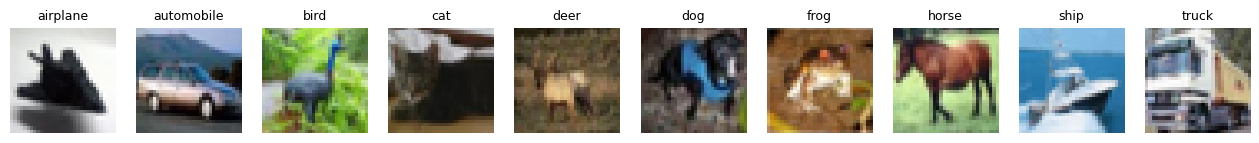

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.ravel(), y_test.ravel()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
print('Training images  :', x_train.shape, y_train.shape)
print('Validation images:', x_test.shape, y_test.shape, '(CIFAR-10 test set)')

fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for c, ax in enumerate(axes):
    ax.imshow(x_train[np.where(y_train == c)[0][0]])
    ax.set_title(class_names[c], fontsize=9)
    ax.axis('off')
plt.show()

### 1(i) CNN architecture

| Layer | Type | Settings |
|---|---|---|
| a | Conv2D | 64 filters, 5×5, ReLU, input shape (32, 32, 3) |
| b | MaxPooling2D | 2×2 |
| c | Conv2D | 32 filters, 3×3, ReLU |
| d | MaxPooling2D | 2×2 |
| e | Conv2D | 32 filters, 3×3, ReLU |
| f | Flatten | |
| g | Dense | 64 neurons, ReLU |
| h | Dense | 10 neurons, softmax (class probabilities) |

The model is compiled with the Adam optimizer and sparse categorical cross-entropy loss (labels are integers 0–9).

In [3]:
model = keras.Sequential([
    keras.Input(shape=x_train.shape[1:]),                  # (32, 32, 3)
    layers.Conv2D(64, (5, 5), activation='relu'),          # a
    layers.MaxPooling2D((2, 2)),                           # b
    layers.Conv2D(32, (3, 3), activation='relu'),          # c
    layers.MaxPooling2D((2, 2)),                           # d
    layers.Conv2D(32, (3, 3), activation='relu'),          # e
    layers.Flatten(),                                      # f
    layers.Dense(64, activation='relu'),                   # g
    layers.Dense(10, activation='softmax'),                # h
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 12, 12, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,058 (258.04 KB)

 Trainable params: 66,058 (258.04 KB)

 Non-trainable params: 0 (0.00 B)

Output shapes: 32×32 → 28×28 after the 5×5 convolution (no padding), 14×14 after pooling, 12×12 after the 3×3 convolution, 6×6 after pooling, and 4×4 after the last 3×3 convolution. The flattened vector therefore has 4 × 4 × 32 = 512 elements.

### 1(ii) Training and validation accuracy after 10 epochs (batch size 64)

In [4]:
history = model.fit(x_train, y_train, epochs=10, batch_size=64,
                    validation_data=(x_test, y_test), verbose=2)
h = history.history

Epoch 1/10


782/782 - 14s - 18ms/step - accuracy: 0.4007 - loss: 1.6267 - val_accuracy: 0.4827 - val_loss: 1.4321


Epoch 2/10


782/782 - 12s - 16ms/step - accuracy: 0.5244 - loss: 1.3276 - val_accuracy: 0.5385 - val_loss: 1.2974


Epoch 3/10


782/782 - 13s - 17ms/step - accuracy: 0.5719 - loss: 1.2038 - val_accuracy: 0.5779 - val_loss: 1.1917


... (10 outputs left out)

Epoch 9/10


782/782 - 13s - 17ms/step - accuracy: 0.6966 - loss: 0.8691 - val_accuracy: 0.6579 - val_loss: 0.9785


Epoch 10/10


782/782 - 13s - 17ms/step - accuracy: 0.7093 - loss: 0.8359 - val_accuracy: 0.6633 - val_loss: 0.9733


In [5]:
train_loss, train_acc = model.evaluate(x_train, y_train, verbose=0)
val_loss, val_acc = model.evaluate(x_test, y_test, verbose=0)
print(f'After 10 epochs:')
print(f'  Training accuracy  : {train_acc:.4f}   (training loss {train_loss:.4f})')
print(f'  Validation accuracy: {val_acc:.4f}   (validation loss {val_loss:.4f})')

pd.DataFrame({'epoch': np.arange(1, 11), 'train accuracy': h['accuracy'], 'val accuracy': h['val_accuracy'],
              'train loss': h['loss'], 'val loss': h['val_loss']}).round(4)

After 10 epochs:
  Training accuracy  : 0.7184   (training loss 0.8049)
  Validation accuracy: 0.6633   (validation loss 0.9733)


,epoch,train accuracy,val accuracy,train loss,val loss
0,1,0.4007,0.4827,1.6267,1.4321
1,2,0.5244,0.5385,1.3276,1.2974
2,3,0.5719,0.5779,1.2038,1.1917
3,4,0.6048,0.5977,1.1143,1.1360
4,5,0.6288,0.6067,1.0510,1.1272
5,6,0.6501,0.6174,0.9951,1.0865
6,7,0.6671,0.6359,0.9494,1.0475
7,8,0.6858,0.6444,0.9028,1.0187
8,9,0.6966,0.6579,0.8691,0.9785
9,10,0.7093,0.6633,0.8359,0.9733


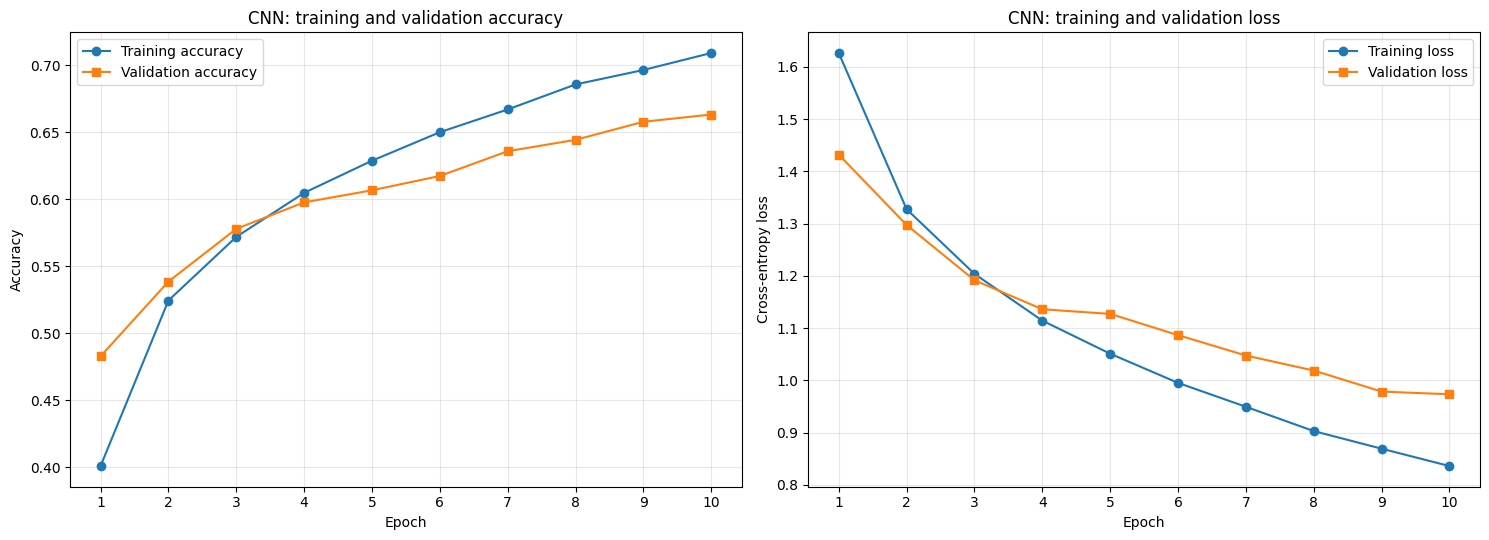

In [6]:
epochs = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].plot(epochs, h['accuracy'], 'o-', label='Training accuracy')
axes[0].plot(epochs, h['val_accuracy'], 's-', label='Validation accuracy')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('CNN: training and validation accuracy')
axes[1].plot(epochs, h['loss'], 'o-', label='Training loss')
axes[1].plot(epochs, h['val_loss'], 's-', label='Validation loss')
axes[1].set_ylabel('Cross-entropy loss')
axes[1].set_title('CNN: training and validation loss')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.set_xticks(epochs)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

Validation accuracy computed from predictions: 0.6633


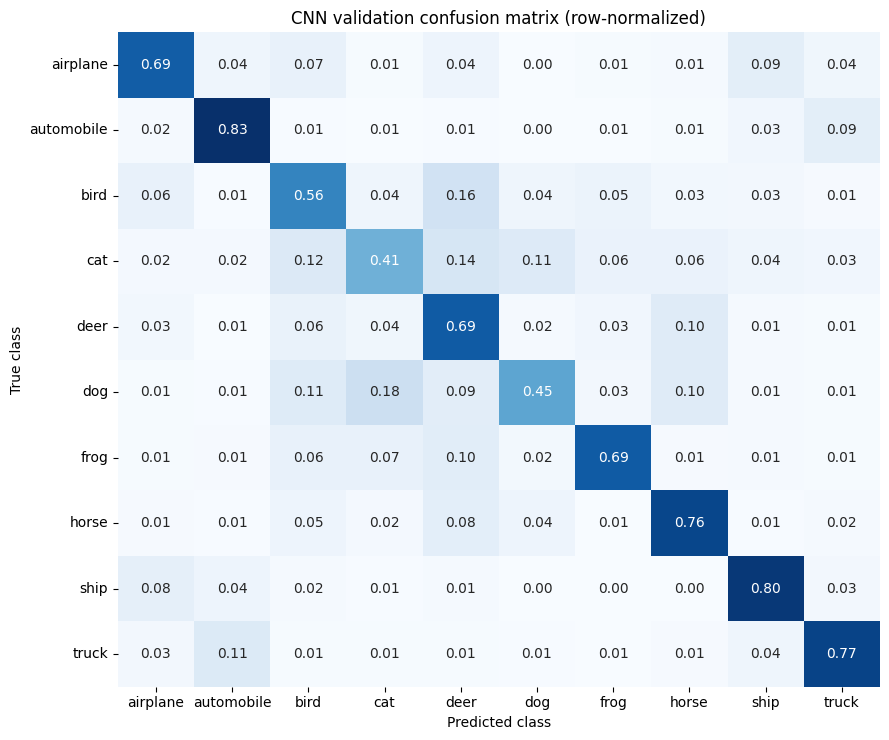

In [7]:
val_pred = model.predict(x_test, verbose=0).argmax(axis=1)
print(f'Validation accuracy computed from predictions: {np.mean(val_pred == y_test):.4f}')

cm = confusion_matrix(y_test, val_pred, normalize='true')
plt.figure(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title('CNN validation confusion matrix (row-normalized)')
plt.tight_layout()
plt.show()